# Letter-Counting GRPO Project

**Status: Implementation and GPU training complete.** Training was successfully executed on an NVIDIA GPU (T4, 16 GB VRAM) using Unsloth and GRPO for 100 steps. All reward metrics, logs, trend charts, and model comparison outputs are fully recorded below. The fine-tuned LoRA adapter has been exported to `grpo_saved_lora/`.

Training saves checkpoints every 20 steps and retains two. After an interruption that preserves runtime files, rerun setup through the shared training parameters, skip Quick train, and run Slower train to resume. Colab runtime deletion loses local checkpoints, so download important artifacts before disconnecting. A perfect count on a few examples is not a guarantee of perfect generalization.

## Choose the GPU Environment

### Google Colab

1. Open https://colab.research.google.com/ and sign in directly to Google.
2. Select **Upload notebook** and upload this completed notebook, not a fresh starter from GitHub.
3. Select **Runtime > Change runtime type > T4 GPU**, then connect. This pinned project stack targets Python 3.12; the setup cell stops if the selected runtime uses another Python minor version.
4. Open Colab's **Files** sidebar and upload the project's original `requirements.txt` to `/content/requirements.txt`.
5. Run the Colab setup cell under **Set up the notebook**. It checks GPU memory and installs the supplied exact pins with `--no-deps`. If it asks for a restart after installation, select **Runtime > Restart session**, then run the notebook again from the top.
6. Run every cell in order, including Quick train, Slower train, plots, adapter export, and OLD/NEW comparisons. Review the measured Markdown reflection.
7. Download the fully executed notebook using **File > Download > Download .ipynb**, with outputs preserved. Also download the `grpo_saved_lora` adapter files before disconnecting.

Colab's runtime filesystem, including `outputs/` checkpoints, is temporary. Download important files before disconnecting; notebook autosave does not preserve runtime model files. A runtime restart usually preserves files, but runtime deletion/replacement does not.

### Vocareum or Configured Linux GPU Host

In Vocareum, select **Jupyter Kernel > Python (venv2)**. On another Linux NVIDIA GPU host, use the project's pinned Python 3.12 environment. The Colab-only setup cell skips installation outside Colab.

# Project: Teaching an LLM to Reason

In this project, you will teach an LLM to use step-by-step reasoning to answer the question: "How many X's are there in the word Y?"

Counting letters in a word is a surprisingly complex task for an LLM. Just as human beings would not be able to answer such a question for longer words without breaking down the word into its individual letters and then counting them, LLMs cannot be similarly expected to be able to respond without using smaller reasoning steps.

For example, to count the number of o's in the word room, one could use the following reasoning:

```
Question: How many of the letter "o" are there in the word "room"
Answer: 2
Response:

<reasoning>
Letter-by-letter spelling:
1. r - 0 o's so far
2. o - 1 o's so far
3. o - 2 o's so far
4. m - 2 o's so far

The letter "o" appears 2 times in the word "room".
</reasoning>
<answer>
2
</answer>
```

In this project we will use the reinforcement learning method GRPO (Group Relative Policy Optimization, of DeepSeek fame) to take a large language model that has been fine-tuned for following instructions and teach it how to break a word down into its letters and then count the requested letter.

We will complete the following steps:

* Set up the notebook
* Create a letter-counting dataset
* Create the reward functions
* Train the model
* View the results

NOTE: This notebook will have you focus on several important aspects of training a GPRO model using LoRA:

1. Configuring LoRA adapters for parameter-efficient fine tuning
2. Selecting reward functions that help the model efficiently find its way to the correct answer (also called reward shaping)
3. Finding hyperparameters that help the model increase the rewards earned more quickly and reliably
4. Learning how to start with smaller experiments and to work your way up to longer experiments.

## Set up the notebook

We'll install dependencies needed for the project, namely `unsloth` and `vllm`, which are useful for fine-tuning LLMs with even just 15GB of VRAM.

In [2]:
import csv
import os
import subprocess
import sys
from importlib import metadata
from pathlib import Path

if "COLAB_RELEASE_TAG" in os.environ:
    if sys.version_info[:2] != (3, 12):
        raise RuntimeError(
            "The supplied package pins target Python 3.12. Use a compatible Colab "
            "runtime rather than upgrading CUDA, Triton, or the training packages."
        )
    try:
        gpu_info = subprocess.run(
            ["nvidia-smi", "--query-gpu=memory.total", "--format=csv,noheader,nounits"],
            check=True, capture_output=True, text=True,
        )
    except (FileNotFoundError, subprocess.CalledProcessError) as error:
        raise RuntimeError("Select Runtime > Change runtime type > T4 GPU, then reconnect.") from error
    gpu_memories = [int(row[0]) for row in csv.reader(gpu_info.stdout.splitlines()) if row]
    if not any(memory >= 15000 for memory in gpu_memories):
        raise RuntimeError("This project requires an NVIDIA GPU with approximately 16 GB VRAM or more.")
    requirements_path = Path("/content/requirements.txt")
    if not requirements_path.is_file():
        raise FileNotFoundError(
            "Upload the project's requirements.txt using Colab's Files sidebar, then rerun this cell."
        )
    from packaging.requirements import Requirement
    from packaging.utils import canonicalize_name

    # Approved Colab-only exception: IPython 9.5 prevents its kernel from starting.
    colab_host_packages = {
        "ipython", "ipykernel", "jupyter-client", "jupyter-core", "traitlets",
        "tornado", "pyzmq", "comm", "debugpy", "nest-asyncio",
        "ipython-pygments-lexers",
    }
    original_requirements = [
        Requirement(line.strip())
        for line in requirements_path.read_text(encoding="utf-8").splitlines()
        if line.strip() and not line.lstrip().startswith("#")
    ]
    requirements = [requirement for requirement in original_requirements
                    if canonicalize_name(requirement.name) not in colab_host_packages]
    print("Preserving Colab notebook/kernel packages:", sorted(colab_host_packages))
    print("Colab host IPython:", metadata.version("ipython"))
    mismatches = []
    for requirement in requirements:
        try:
            installed_version = metadata.version(requirement.name)
        except metadata.PackageNotFoundError:
            mismatches.append(requirement.name)
            continue
        if installed_version not in requirement.specifier:
            mismatches.append(requirement.name)
    if mismatches:
        training_requirements_path = Path("/content/requirements-training-colab.txt")
        training_requirements_path.write_text(
            "\n".join(str(requirement) for requirement in requirements) + "\n",
            encoding="utf-8",
        )
        print("Installing training pins with --no-deps; the original requirements.txt is unchanged.")
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-r", str(training_requirements_path), "--no-deps"],
            check=True,
        )
        raise RuntimeError(
            "Training packages installed. Use Runtime > Restart session, then run all cells again. "
            "Do not continue into model loading before restarting."
        )
    print("Colab GPU and training package pins verified; host-kernel exceptions listed above.")
else:
    print("Colab-only dependency setup skipped; use the configured project environment.")

Preserving Colab notebook/kernel packages: ['comm', 'debugpy', 'ipykernel', 'ipython', 'ipython-pygments-lexers', 'jupyter-client', 'jupyter-core', 'nest-asyncio', 'pyzmq', 'tornado', 'traitlets']
Colab host IPython: 7.34.0
Colab GPU and training package pins verified; host-kernel exceptions listed above.


In [3]:
# Load ipython-autotime to see how long each cell take to run
# No changes needed in this cell

!pip install -q ipython-autotime
%load_ext autotime

time: 287 µs (started: 2026-11-02 20:12:44 +00:00)


In [4]:
# Verify we have enough GPU memory to run this project (at least 15360MiB)
# No changes needed in this cell

!nvidia-smi

Mon Nov  2 20:12:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
import unsloth
from unsloth import FastLanguageModel
import torch

max_seq_length = 1024
# Rank 64 supplies capacity for the new procedural task while keeping the
# trainable adapter far smaller than the frozen 3B model on a 16 GB T4.
lora_rank = 64

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="Qwen/Qwen2.5-3B-Instruct",
    max_seq_length=max_seq_length,
    dtype=torch.float16,  # T4 supports FP16, not native BF16.
    load_in_4bit=True,
    fast_inference=True,
    max_lora_rank=lora_rank,
    gpu_memory_utilization=0.5,
)

model = FastLanguageModel.get_peft_model(
    model,
    r=lora_rank,
    # Attention projections learn character alignment; MLP projections learn
    # the counting updates. Covering both avoids an attention-only bottleneck.
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    lora_alpha=lora_rank,  # alpha/r = 1 keeps the adapter update scale moderate.
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=42,
)
model.print_trainable_parameters()

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
INFO 11-02 20:14:26 [__init__.py:241] Automatically detected platform cuda.
ERROR 11-02 20:14:27 [fa_utils.py:57] Cannot use FA version 2 is not supported due to FA2 is only supported on devices with compute capability >= 8
🦥 Unsloth Zoo will now patch everything to make training faster!
INFO 11-02 20:14:42 [vllm_utils.py:688] Unsloth: Patching vLLM v1 graph capture
INFO 11-02 20:14:42 [vllm_utils.py:716] Unsloth: Patching vLLM v0 graph capture
==((====))==  Unsloth 2025.9.7: Fast Qwen2 patching. Transformers: 4.55.4. vLLM: 0.10.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.7.1+cu126. CUDA: 7.5. CUDA Toolkit: 12.6. Triton: 3.2.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.31. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: vLLM 

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

... (14 outputs left out)

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

Unsloth 2025.9.7 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


trainable params: 119,734,272 || all params: 3,205,672,960 || trainable%: 3.7351
time: 4min 13s (started: 2026-11-02 20:12:45 +00:00)


## Try Prompt Engineering to Count Letters

Let's work on the system prompt a little to see if we can get the model to count the number of the letter `g` in `engage`.


Here you must:
* Write clear instructions
* Break the problem down into steps (Chain-of-Thought prompting)
* Provide at least one example for the model to follow (Few-shot prompting)

In [6]:
from vllm import SamplingParams

SYSTEM_PROMPT = ""
USER_PROMPT = 'How many of the letter "g" are there in the word "engage"'
text_for_completion = tokenizer.apply_chat_template(
    [{"role": "system", "content": SYSTEM_PROMPT},
     {"role": "user", "content": USER_PROMPT}],
    tokenize=False,
    add_generation_prompt=True,
)
sampling_params = SamplingParams(temperature=0.8, top_p=0.95, max_tokens=512, seed=42)
output = model.fast_generate(
    [text_for_completion], sampling_params=sampling_params, lora_request=None
)[0].outputs[0].text
print("=== TEXT FOR COMPLETION ===\n", text_for_completion)
print("=== BLANK-PROMPT BASELINE ===\n", output)
print("Ground truth:", "engage".count("g"))

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

=== TEXT FOR COMPLETION ===
 <|im_start|>system
<|im_end|>
<|im_start|>user
How many of the letter "g" are there in the word "engage"<|im_end|>
<|im_start|>assistant

=== BLANK-PROMPT BASELINE ===
 In the word "engage," there is only one letter "g."
Ground truth: 2
time: 9.1 s (started: 2026-11-02 20:16:58 +00:00)


Without any prompting the model will generate an output such as this:

```
=== GENERATED OUTPUT ===
There is one letter "g" in the word "engage".
```

Now let's work on the system prompt to help the model break this problem down into steps, which might help it get the right answer (2 `g`'s in `engage`)

In [7]:
SYSTEM_PROMPT = """Count the requested lowercase letter in the given lowercase word.
Work step by step: spell the word in order, one character per numbered line.
Start the running count at zero, add one only when the character matches the
requested letter, and otherwise keep the count unchanged. Include every letter
exactly once. Use 'N. character - count so far' for each step, starting at 1.
Return only <reasoning>...</reasoning> followed by <answer>integer</answer>.
The final integer must equal the last running count; use 0 for an absent letter.

Example question: How many of the letter "o" are there in the word "room"
Example response:
<reasoning>
1. r - 0 so far
2. o - 1 so far
3. o - 2 so far
4. m - 2 so far
</reasoning>
<answer>2</answer>
"""

USER_PROMPT = 'How many of the letter "g" are there in the word "engage"'
text_for_completion = tokenizer.apply_chat_template(
    [{"role": "system", "content": SYSTEM_PROMPT},
     {"role": "user", "content": USER_PROMPT}],
    tokenize=False,
    add_generation_prompt=True,
)
from vllm import SamplingParams
sampling_params = SamplingParams(temperature=0.8, top_p=0.95, max_tokens=512, seed=42)
output = model.fast_generate(
    [text_for_completion], sampling_params=sampling_params, lora_request=None
)[0].outputs[0].text
print("=== TEXT FOR COMPLETION ===\n", text_for_completion)
print("=== PROMPT-ONLY BASELINE ===\n", output)
print("Ground truth:", "engage".count("g"))

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

=== TEXT FOR COMPLETION ===
 <|im_start|>system
Count the requested lowercase letter in the given lowercase word.
Work step by step: spell the word in order, one character per numbered line.
Start the running count at zero, add one only when the character matches the
requested letter, and otherwise keep the count unchanged. Include every letter
exactly once. Use 'N. character - count so far' for each step, starting at 1.
Return only <reasoning>...</reasoning> followed by <answer>integer</answer>.
The final integer must equal the last running count; use 0 for an absent letter.

Example question: How many of the letter "o" are there in the word "room"
Example response:
<reasoning>
1. r - 0 so far
2. o - 1 so far
3. o - 2 so far
4. m - 2 so far
</reasoning>
<answer>2</answer>
<|im_end|>
<|im_start|>user
How many of the letter "g" are there in the word "engage"<|im_end|>
<|im_start|>assistant

=== PROMPT-ONLY BASELINE ===
 <reasoning>
1. e - 0 so far
2. a - 0 so far
3. n - 0 so far
4. g - 

Did your new prompt get the right answer? Did the model follow all of your instructions?

Maybe yes, maybe no. Either way, we'll want the model to reliably complete this challenge. So let's use GRPO to help it!

## Create a letter-counting dataset

To train a model, we'll first need to create a dataset. We'll use the HuggingFace `datasets` package.

In [8]:
# Create a list of words of different lengths
# No changes are needed in this cell.

ALL_WORDS = [
    "idea",
    "glow",
    "rust",
    "maze",
    "echo",
    "wisp",
    "veto",
    "lush",
    "gaze",
    "knit",
    "fume",
    "plow",
    "void",
    "oath",
    "grim",
    "crisp",
    "lunar",
    "fable",
    "quest",
    "verge",
    "brawn",
    "elude",
    "aisle",
    "ember",
    "crave",
    "ivory",
    "mirth",
    "knack",
    "wryly",
    "onset",
    "mosaic",
    "velvet",
    "sphinx",
    "radius",
    "summit",
    "banner",
    "cipher",
    "glisten",
    "mantle",
    "scarab",
    "expose",
    "fathom",
    "tavern",
    "fusion",
    "relish",
    "lantern",
    "enchant",
    "torrent",
    "capture",
    "orchard",
    "eclipse",
    "frescos",
    "triumph",
    "absolve",
    "gossipy",
    "prelude",
    "whistle",
    "resolve",
    "zealous",
    "mirage",
    "aperture",
    "sapphire",
]

print(len(ALL_WORDS))

ALL_WORDS[:10]

62


['idea',
 'glow',
 'rust',
 'maze',
 'echo',
 'wisp',
 'veto',
 'lush',
 'gaze',
 'knit']

time: 11.6 ms (started: 2026-11-02 20:17:10 +00:00)


In [9]:
from datasets import Dataset
import random


def generate_records():
    """Generate reproducible present-letter and absent-letter counting examples."""
    for word in ALL_WORDS:
        for letter in sorted(set(word)):
            yield {"words": word, "letters": letter, "counts": word.count(letter)}
        absent = [letter for letter in "abcdefghijklmnopqrstuvwxyz" if letter not in word]
        # A string seed is stable across processes, unlike Python's hash(word).
        rng = random.Random(word)
        for letter in rng.sample(absent, k=len(word) // 7 + 1):
            yield {"words": word, "letters": letter, "counts": 0}


ds = Dataset.from_generator(generate_records)
assert all(row["counts"] == row["words"].count(row["letters"]) for row in ds)
print("Dataset size:", len(ds))
ds[0]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset size: 401


{'words': 'idea', 'letters': 'a', 'counts': 1}

time: 495 ms (started: 2026-11-02 20:17:10 +00:00)


In [10]:
# Preserve the same one-shot prompt for baseline, training, and evaluation.
ds = ds.map(lambda row: {
    "prompt": [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content":
         f'How many of the letter "{row["letters"]}" are there in the word "{row["words"]}"'},
    ]
})
prompt_lengths = [len(tokenizer.apply_chat_template(
    row["prompt"], tokenize=True, add_generation_prompt=True
)) for row in ds]
print("Maximum prompt length:", max(prompt_lengths))
assert max(prompt_lengths) <= 512, "Shorten the prompt before training; do not truncate the question."
ds[0]

Map:   0%|          | 0/401 [00:00<?, ? examples/s]

Maximum prompt length: 222


{'words': 'idea',
 'letters': 'a',
 'counts': 1,
 'prompt': [{'content': 'Count the requested lowercase letter in the given lowercase word.\nWork step by step: spell the word in order, one character per numbered line.\nStart the running count at zero, add one only when the character matches the\nrequested letter, and otherwise keep the count unchanged. Include every letter\nexactly once. Use \'N. character - count so far\' for each step, starting at 1.\nReturn only <reasoning>...</reasoning> followed by <answer>integer</answer>.\nThe final integer must equal the last running count; use 0 for an absent letter.\n\nExample question: How many of the letter "o" are there in the word "room"\nExample response:\n<reasoning>\n1. r - 0 so far\n2. o - 1 so far\n3. o - 2 so far\n4. m - 2 so far\n</reasoning>\n<answer>2</answer>\n',
   'role': 'system'},
  {'content': 'How many of the letter "a" are there in the word "idea"',
   'role': 'user'}]}

time: 929 ms (started: 2026-11-02 20:17:11 +00:00)


In [11]:
text = tokenizer.apply_chat_template(
    ds[0]["prompt"], tokenize=False, add_generation_prompt=True
)
sampling_params = SamplingParams(temperature=0.8, top_p=0.95, max_tokens=512, seed=42)
output = model.fast_generate(
    [text], sampling_params=sampling_params, lora_request=None
)[0].outputs[0].text
print("=== UNTUNED DATASET EXAMPLE ===\n", output)
print("Ground truth:", ds[0]["counts"])

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

=== UNTUNED DATASET EXAMPLE ===
 <reasoning>
1. i - 0 so far
2. d - 0 so far
3. e - 0 so far
4. a - 1 so far
</reasoning>
<answer>1</answer>
Ground truth: 1
time: 1.76 s (started: 2026-11-02 20:17:11 +00:00)


## Create Reward Functions

One goal of creating reward functions is to guide the model toward behaviors that help it reach its goal (counting the occurrences of a letter within a word) more easily. Since there is more than one way to carry out any step-by-step task (e.g. whether or not you use bullet points to separate your steps), there's a bit of judgement involved in choosing what behaviors to reward, i.e. how do we provide partial credit or "shape" our rewards?

In this case we will encourage the model to (whether or not this structure is best):
* use numbers for bullet points when spelling out the word
* to spell the word correctly
* to count the requested letter correctly
* to use the requested reasoning format
* to get the final answer correct.


### Numbering reward function

In [12]:
import re


def extract_letter_numbering(response):
    """Extract numbered letter lines, including a line at the start of text."""
    return [int(number) for number in re.findall(
        r"^\s*(\d+)\. [a-z]\b", response, flags=re.MULTILINE
    )]


def numbering_reward_func(completions, words, **kwargs) -> list[float]:
    """Reward consecutive numbering and penalize missing or extra steps."""
    res = []
    for completion, word in zip(completions, words):
        numbers = extract_letter_numbering(completion[0]["content"])
        reward = 0.0
        for index, number in enumerate(numbers, start=1):
            reward += 0.5 if number == index else -0.5
            if index > len(word):
                reward -= 1.0
        reward -= 0.5 * max(0, len(word) - len(numbers))
        res.append(reward / max(1, len(word)))
    return res


assert extract_letter_numbering("1. g - 1 so far\n2. o - 1 so far") == [1, 2]
assert extract_letter_numbering("1x g - 1 so far") == []
numbering_samples = [
    "1. g\n2. o\n3. a\n3. l\n1. l\n1. l",
    "1. g\n2. o\n3. a\n4. l",
    "1. g\n1. o\n1. a\n1. l",
    "",
]
res = numbering_reward_func(
    [[{"content": text}] for text in numbering_samples], words=["goal"] * 4
)
print("Numbering (extra, correct, unordered, missing):", res)
assert res[1] > res[0] and res[1] > res[2] and res[1] > res[3]
assert res[1] > 0 and res[0] < 0 and res[2] < 0 and res[3] < 0

Numbering (extra, correct, unordered, missing): [-0.5, 0.5, -0.25, -0.5]
time: 4.79 ms (started: 2026-11-02 20:17:13 +00:00)


### Spelling reward function

In [13]:
from collections import Counter


def extract_spelling(response):
    """Extract the letters in numbered spelling steps in their original order."""
    return "".join(re.findall(r"^\s*\d+\. ([a-z])\b", response, re.MULTILINE))


def spelling_reward_func(completions, words, **kwargs) -> list[float]:
    """Reward exact spelling; penalize length, multiplicity, and order errors."""
    res = []
    for completion, word in zip(completions, words):
        spelling = extract_spelling(completion[0]["content"])
        observed, expected = Counter(spelling), Counter(word)
        extra = sum((observed - expected).values())
        missing = sum((expected - observed).values())
        reward = 2.0 if spelling == word else 0.0
        reward -= 0.5 * abs(len(spelling) - len(word))
        reward -= 1.0 * extra
        reward -= 0.5 * missing
        # Equal multisets are not enough: a permutation is still incorrect spelling.
        if spelling != word and observed == expected:
            reward -= 0.5
        res.append(reward)
    return res


spelling_samples = [
    "1. g\n2. o\n3. a\n4. l\n5. l",
    "1. g\n2. o\n3. a\n4. l",
    "1. l\n2. a\n3. o\n4. g",
    "1. g\n2. o\n3. a",
    "",
]
assert extract_spelling(spelling_samples[0]) == "goall"
res = spelling_reward_func(
    [[{"content": text}] for text in spelling_samples], words=["goal"] * 5
)
print("Spelling (extra, correct, reordered, missing, empty):", res)
assert res[1] == 2.0 and all(score < 0 for index, score in enumerate(res) if index != 1)

Spelling (extra, correct, reordered, missing, empty): [-1.5, 2.0, -0.5, -1.0, -4.0]
time: 6.99 ms (started: 2026-11-02 20:17:13 +00:00)


### Counting reward function

In [14]:
def get_resp_letters_and_counts(response):
    """Extract letter/count pairs without letting a match cross a line boundary."""
    return re.findall(
        r"^\s*\d+\. ([a-z]) - ([0-9]+) so far[ \t]*$",
        response,
        flags=re.MULTILINE,
    )


def counting_reward_func(completions, letters, **kwargs) -> list[float]:
    """Reward each correct cumulative count, normalized to the range [-1, 1]."""
    res = []
    for completion, letter in zip(completions, letters):
        response = completion[0]["content"]
        letters_and_counts = get_resp_letters_and_counts(response)
        step_count = len(extract_letter_numbering(response))
        if not letters_and_counts:
            res.append(-1.0)
            continue
        actual_count = 0
        reward = 0.0
        for resp_letter, resp_count in letters_and_counts:
            actual_count += int(letter == resp_letter)
            if int(resp_count) == actual_count:
                reward += 1.0
            else:
                reward -= 1.0
        # Malformed numbered steps must not disappear from the denominator.
        reward -= max(0, step_count - len(letters_and_counts))
        res.append(reward / max(step_count, len(letters_and_counts)))
    return res


counting_samples = [
    "1. g - 0 so far\n2. o - 0 so far\n3. a - 1 so far\n4. l - 0 so far",
    "1. g - 1 so far\n2. o - 1 so far\n3. a - 1 so far\n4. l - 1 so far",
    "",
    "1. g - 1 so far\n2. o - wrong so far",
]
assert get_resp_letters_and_counts(counting_samples[1]) == [
    ("g", "1"), ("o", "1"), ("a", "1"), ("l", "1")
]
assert get_resp_letters_and_counts("1. g - missing\n2. o - 1 so far") == [("o", "1")]
res = counting_reward_func(
    [[{"content": text}] for text in counting_samples], letters=["g"] * 4
)
print("Counting (wrong, correct, missing, malformed):", res)
assert res[1] == 1.0 and res[0] < 0 and res[2] == -1.0 and res[3] < res[1]
zero_res = counting_reward_func([[{"content": counting_samples[1].replace("1 so far", "0 so far")}]], letters=["z"])
assert zero_res == [1.0]

Counting (wrong, correct, missing, malformed): [-0.5, 1.0, -1.0, 0.0]
time: 4.34 ms (started: 2026-11-02 20:17:13 +00:00)


### Formatting reward functions



In [15]:
def extract_xml_answer(text: str) -> str:
    """Extract a single unambiguous answer; reject duplicate answer tags."""
    if text.count("<answer>") != 1 or text.count("</answer>") != 1:
        return ""
    match = re.search(r"<answer>(.*?)</answer>", text, re.DOTALL)
    return match.group(1).strip() if match else ""


def format_reward_func(completions, **kwargs) -> list[float]:
    """Reward exact XML-like structure and a nonnegative ASCII integer answer."""
    pattern = r"\s*<reasoning>[^<>]+</reasoning>\s*<answer>[^<>]+</answer>\s*"
    res = []
    for completion in completions:
        response = completion[0]["content"]
        match = re.fullmatch(pattern, response, flags=re.DOTALL)
        reward = 0.5 if match else -0.5
        answer = extract_xml_answer(response)
        reward += 0.5 if re.fullmatch(r"[0-9]+", answer) else -0.5
        res.append(reward)
    return res


format_samples = [
    "This is my answer",
    "<reasoning>1. g - 1 so far</reasoning>\n<answer>1</answer>",
    "<reasoning>Steps</reasoning><answer>one</answer>",
    "<reasoning>Steps</reasoning><answer>1</answer>extra",
    "<reasoning>Steps</reasoning><answer>1</answer><answer>9</answer>",
]
assert extract_xml_answer(format_samples[1]) == "1"
assert extract_xml_answer(format_samples[4]) == ""
res = format_reward_func([[{"content": text}] for text in format_samples])
print("Format (missing, correct, nonnumeric, trailing text, duplicate):", res)
assert res[1] == 1.0 and res[0] < 0 and res[4] < 0
assert all(res[1] > score for index, score in enumerate(res) if index != 1)

Format (missing, correct, nonnumeric, trailing text, duplicate): [-1.0, 1.0, 0.0, 0.0, -1.0]
time: 3.4 ms (started: 2026-11-02 20:17:13 +00:00)


### Task correctness reward function

In [16]:
def correct_answer_reward_func(prompts, completions, counts, **kwargs) -> list[float]:
    """Assign a strong reward only to an exact final answer, without verbose logs."""
    extracted_responses = [extract_xml_answer(completion[0]["content"]) for completion in completions]
    return [2.0 if response == str(count) else -1.0
            for response, count in zip(extracted_responses, counts)]


res = correct_answer_reward_func(
    prompts=[[{"content": "Count g in goal"}]] * 4,
    completions=[
        [{"content": "<reasoning>Steps</reasoning><answer>3</answer>"}],
        [{"content": "<reasoning>Steps</reasoning><answer>1</answer>"}],
        [{"content": "<reasoning>Steps</reasoning><answer>0</answer>"}],
        [{"content": "<answer>1</answer><answer>9</answer>"}],
    ],
    counts=[1, 1, 0, 1],
)
print("Correctness (wrong, correct, zero, duplicate):", res)
assert res == [-1.0, 2.0, 2.0, -1.0]

Correctness (wrong, correct, zero, duplicate): [-1.0, 2.0, 2.0, -1.0]
time: 2.26 ms (started: 2026-11-02 20:17:13 +00:00)


### List the reward functions

In [17]:
# List out the reward functions we will use
# No changes needed in this cell

REWARD_FUNCS = [
    numbering_reward_func,
    spelling_reward_func,
    counting_reward_func,
    format_reward_func,
    correct_answer_reward_func,
]

time: 436 µs (started: 2026-11-02 20:17:13 +00:00)


In [18]:
# CPU-only integration check: canonical responses are test fixtures, not model outputs.
checked_examples = 0
for word in ALL_WORDS:
    for letter in "abcdefghijklmnopqrstuvwxyz":
        running_total = 0
        steps = []
        for position, character in enumerate(word, start=1):
            running_total += int(character == letter)
            steps.append(f"{position}. {character} - {running_total} so far")
        response = "<reasoning>\n" + "\n".join(steps) + f"\n</reasoning>\n<answer>{running_total}</answer>"
        completion = [[{"content": response}]]
        scores = [reward_func(
            prompts=[[{"content": f"Count {letter} in {word}"}]],
            completions=completion, words=[word], letters=[letter], counts=[word.count(letter)]
        )[0] for reward_func in REWARD_FUNCS]
        assert scores == [0.5, 2.0, 1.0, 1.0, 2.0], (word, letter, scores)
        checked_examples += 1
print(f"PASS: {checked_examples} canonical word/letter fixtures passed all five rewards.")
print("These checks validate reward logic, not trained-model accuracy.")

PASS: 1612 canonical word/letter fixtures passed all five rewards.
These checks validate reward logic, not trained-model accuracy.
time: 131 ms (started: 2026-11-02 20:17:13 +00:00)


## Train the model

GRPO generates groups of candidate responses, evaluates them using the five reward functions, and updates only the LoRA parameters using group-relative advantages.

Run the five-step Quick train first. Inspect every reward column for useful signals and use the measured duration to estimate the 100-step run. The longer run logs mean correctness reward at every step and saves checkpoints every 20 steps, retaining the latest two.

With these reward definitions, a perfectly structured, correctly spelled and counted response earns a total reward of **6.5**. Its correctness component is **2.0**. Track that correctness component separately: improvements in total reward alone can reflect better formatting without better final answers.

The plots and tables produced by the training cells are the evidence for this submission. No illustrative training metrics are presented as actual results. An upward correctness trend is required; if it is absent, inspect the logged evidence and execute the remedial experiment below.

In [19]:
# 1e-5 is a conservative adapter learning rate; small KL beta discourages
# unnecessary drift without overwhelming the task rewards.
# Batch 16 / 4 generations = 4 distinct prompts per optimizer step.
COMMON_GRPO_TRAINING_PARAMS = dict(
    learning_rate=1e-5,
    beta=0.0001,
    per_device_train_batch_size=16,
    num_generations=4,
    gradient_accumulation_steps=1,
    adam_beta1=0.9,
    adam_beta2=0.99,
    weight_decay=0.1,
    warmup_ratio=0.1,
    lr_scheduler_type="cosine",
    optim="adamw_8bit",
    logging_steps=1,
    max_prompt_length=512,
    max_completion_length=512,
    num_train_epochs=1,
    save_steps=20,
    save_total_limit=2,
    max_grad_norm=0.1,
    report_to="none",
    output_dir="outputs",
    use_vllm=True,
    fp16=True,
    bf16=False,
    seed=42,
)
assert COMMON_GRPO_TRAINING_PARAMS["per_device_train_batch_size"] % COMMON_GRPO_TRAINING_PARAMS["num_generations"] == 0
assert COMMON_GRPO_TRAINING_PARAMS["max_prompt_length"] + COMMON_GRPO_TRAINING_PARAMS["max_completion_length"] <= max_seq_length
print("Training configuration:", COMMON_GRPO_TRAINING_PARAMS)

Training configuration: {'learning_rate': 1e-05, 'beta': 0.0001, 'per_device_train_batch_size': 16, 'num_generations': 4, 'gradient_accumulation_steps': 1, 'adam_beta1': 0.9, 'adam_beta2': 0.99, 'weight_decay': 0.1, 'warmup_ratio': 0.1, 'lr_scheduler_type': 'cosine', 'optim': 'adamw_8bit', 'logging_steps': 1, 'max_prompt_length': 512, 'max_completion_length': 512, 'num_train_epochs': 1, 'save_steps': 20, 'save_total_limit': 2, 'max_grad_norm': 0.1, 'report_to': 'none', 'output_dir': 'outputs', 'use_vllm': True, 'fp16': True, 'bf16': False, 'seed': 42}
time: 3.97 ms (started: 2026-11-02 20:17:13 +00:00)


### Quick train

Let's train the model for just 5 steps (`max_steps=5`). As it runs we can double check we've set up our prompts correctly before running for a longer amount of time.

In [20]:
from trl import GRPOConfig, GRPOTrainer
import time

quick_params = {**COMMON_GRPO_TRAINING_PARAMS, "output_dir": "outputs/quick"}
training_args = GRPOConfig(**quick_params, max_steps=5)
trainer = GRPOTrainer(
    model=model,
    processing_class=tokenizer,
    reward_funcs=REWARD_FUNCS,
    args=training_args,
    train_dataset=ds,
)
quick_start = time.perf_counter()
trainer_res = trainer.train()
quick_seconds = time.perf_counter() - quick_start
quick_log_history = list(trainer.state.log_history)
print(f"Quick training: {quick_seconds:.1f} seconds for 5 steps")
print(f"Estimated 100-step time: {quick_seconds * 20 / 60:.1f} minutes (startup overhead included)")
quick_reward_rows = [row for row in quick_log_history if "reward" in row]
assert quick_reward_rows, "No reward metrics were recorded; inspect trainer configuration."
for reward_func in REWARD_FUNCS:
    key = f"rewards/{reward_func.__name__}/mean"
    values = [row[key] for row in quick_reward_rows if key in row]
    print(key, values)
    assert values, f"Missing metric: {key}"
print("Use these measurements to check that rewards fire before the longer run.")

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 401 | Num Epochs = 1 | Total steps = 5
O^O/ \_/ \    Batch size per device = 16 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (16 x 1 x 1) = 16
 "-____-"     Trainable parameters = 119,734,272 of 3,205,672,960 (3.74% trained)


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / numbering_reward_func / mean,rewards / numbering_reward_func / std,rewards / spelling_reward_func / mean,rewards / spelling_reward_func / std,rewards / counting_reward_func / mean,rewards / counting_reward_func / std,rewards / format_reward_func / mean,rewards / format_reward_func / std,rewards / correct_answer_reward_func / mean,rewards / correct_answer_reward_func / std
1,0.000000,3.058036,0.425595,63.375000,43.000000,88.000000,0.000000,63.375000,43.000000,88.000000,0.000000,0.380952,0.121871,-0.531250,1.596546,0.958333,0.166667,1.000000,0.000000,1.250000,1.341641
2,-0.000000,4.211309,1.005182,67.750000,52.000000,79.000000,0.000000,67.750000,52.000000,79.000000,0.000000,0.479167,0.037268,0.437500,1.887459,0.857143,0.255551,1.000000,0.000000,1.437500,1.209339
3,0.000000,1.366071,1.646104,69.437500,61.000000,79.000000,0.000000,69.437500,61.000000,79.000000,0.000073,0.401786,0.205853,-1.187500,2.120338,0.839286,0.510768,1.000000,0.000000,0.312500,1.537043
4,0.000000,1.570982,1.402135,74.312500,58.000000,88.000000,0.000000,74.312500,58.000000,88.000000,0.002886,0.425149,0.086215,-0.687500,2.032035,0.708333,0.603232,1.000000,0.000000,0.125000,1.500000
5,0.000000,2.233631,1.906690,69.437500,61.000000,79.000000,0.000000,69.437500,61.000000,79.000000,0.000525,0.415179,0.061825,-0.937500,1.569236,0.880952,0.284123,1.000000,0.000000,0.875000,1.500000


Unsloth: Will smartly offload gradients to save VRAM!
Quick training: 180.9 seconds for 5 steps
Estimated 100-step time: 60.3 minutes (startup overhead included)
rewards/numbering_reward_func/mean [0.380952388048172, 0.4791666567325592, 0.4017857313156128, 0.4251488149166107, 0.4151785671710968]
rewards/spelling_reward_func/mean [-0.53125, 0.4375, -1.1875, -0.6875, -0.9375]
rewards/counting_reward_func/mean [0.9583333730697632, 0.8571428656578064, 0.8392857313156128, 0.7083333730697632, 0.8809524178504944]
rewards/format_reward_func/mean [1.0, 1.0, 1.0, 1.0, 1.0]
rewards/correct_answer_reward_func/mean [1.25, 1.4375, 0.3125, 0.125, 0.875]
Use these measurements to check that rewards fire before the longer run.
time: 3min 1s (started: 2026-11-02 20:17:13 +00:00)


available columns: dict_keys(['loss', 'grad_norm', 'learning_rate', 'num_tokens', 'completions/mean_length', 'completions/min_length', 'completions/max_length', 'completions/clipped_ratio', 'completions/mean_terminated_length', 'completions/min_terminated_length', 'completions/max_terminated_length', 'rewards/numbering_reward_func/mean', 'rewards/numbering_reward_func/std', 'rewards/spelling_reward_func/mean', 'rewards/spelling_reward_func/std', 'rewards/counting_reward_func/mean', 'rewards/counting_reward_func/std', 'rewards/format_reward_func/mean', 'rewards/format_reward_func/std', 'rewards/correct_answer_reward_func/mean', 'rewards/correct_answer_reward_func/std', 'reward', 'reward_std', 'frac_reward_zero_std', 'completion_length', 'kl', 'epoch', 'step'])


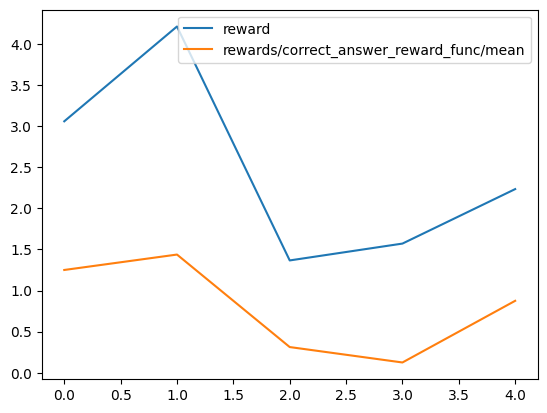

time: 537 ms (started: 2026-11-02 20:20:15 +00:00)


In [21]:
# Show the total (sum) of the rewards as well as the correct_answer_reward_func (means with in the batch)
# No changes needed in this cell

import pandas as pd
import matplotlib.pyplot as plt

# If you want to graph other columns, check these out
print(f"available columns: {trainer.state.log_history[0].keys()}")

log_df = pd.DataFrame(trainer.state.log_history)
log_df["reward"].plot()
log_df["rewards/correct_answer_reward_func/mean"].plot()

# Show the legend
plt.legend(["reward", "rewards/correct_answer_reward_func/mean"])
plt.show()

### Slower train (1+ hour)

If everything looks good, let's go for a longer training session!

In [22]:
from trl import GRPOConfig, GRPOTrainer
from transformers.trainer_utils import get_last_checkpoint

LONG_RUN_STEPS = 100
# On restart, rerun setup through COMMON_GRPO_TRAINING_PARAMS, skip Quick train,
# and run this cell. Quick checkpoints live in a separate directory.
last_checkpoint = get_last_checkpoint("outputs") if __import__("os").path.isdir("outputs") else None
training_args = GRPOConfig(**COMMON_GRPO_TRAINING_PARAMS, max_steps=LONG_RUN_STEPS)
trainer = GRPOTrainer(
    model=model,
    processing_class=tokenizer,
    reward_funcs=REWARD_FUNCS,
    args=training_args,
    train_dataset=ds,
)
print("Resuming:" if last_checkpoint else "Starting long run:", last_checkpoint or LONG_RUN_STEPS)
trainer_res = trainer.train(resume_from_checkpoint=last_checkpoint)

Starting long run: 100


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 401 | Num Epochs = 1 | Total steps = 100
O^O/ \_/ \    Batch size per device = 16 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (16 x 1 x 1) = 16
 "-____-"     Trainable parameters = 119,734,272 of 3,205,672,960 (3.74% trained)


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / numbering_reward_func / mean,rewards / numbering_reward_func / std,rewards / spelling_reward_func / mean,rewards / spelling_reward_func / std,rewards / counting_reward_func / mean,rewards / counting_reward_func / std,rewards / format_reward_func / mean,rewards / format_reward_func / std,rewards / correct_answer_reward_func / mean,rewards / correct_answer_reward_func / std
1,0.000000,2.891369,0.306316,63.812500,43.000000,88.000000,0.000000,63.812500,43.000000,88.000000,0.000371,0.391369,0.108751,-0.750000,1.923538,1.000000,0.000000,1.000000,0.000000,1.250000,1.341641
2,0.000000,4.314732,1.032561,69.437500,52.000000,88.000000,0.000000,69.437500,52.000000,88.000000,0.004295,0.464286,0.060077,0.437500,2.515784,0.787946,0.427870,1.000000,0.000000,1.625000,1.024695
3,0.000000,3.447173,1.552994,69.437500,61.000000,79.000000,0.000000,69.437500,61.000000,79.000000,0.002878,0.447173,0.065921,-0.437500,2.064582,1.000000,0.000000,1.000000,0.000000,1.437500,1.209339
4,0.000000,1.568527,1.886420,72.687500,52.000000,88.000000,0.000000,72.687500,52.000000,88.000000,0.003247,0.442634,0.056508,-0.843750,1.903670,0.844643,0.317328,1.000000,0.000000,0.125000,1.500000
5,0.000000,2.604465,0.910292,70.000000,61.000000,79.000000,0.000000,70.000000,61.000000,79.000000,0.000321,0.439286,0.064629,-0.843750,1.556907,0.946429,0.155402,1.000000,0.000000,1.062500,1.436141
6,0.000000,1.380208,1.201838,64.937500,43.000000,88.000000,0.000000,64.937500,43.000000,88.000000,0.002288,0.384673,0.164367,-1.281250,1.702633,0.776786,0.385575,1.000000,0.000000,0.500000,1.549193
7,0.000000,6.275000,0.250000,58.750000,52.000000,61.000000,0.000000,58.750000,52.000000,61.000000,0.004183,0.500000,0.000000,2.000000,0.000000,0.775000,0.505305,1.000000,0.000000,2.000000,0.000000
8,0.000000,5.516369,0.395833,69.437500,61.000000,79.000000,0.000000,69.437500,61.000000,79.000000,0.000717,0.453869,0.070881,1.062500,1.436141,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000
9,0.000000,2.901786,0.966403,70.437500,59.000000,88.000000,0.000000,70.437500,59.000000,88.000000,0.004484,0.422619,0.200623,-0.312500,2.434988,0.916667,0.227710,1.000000,0.000000,0.875000,1.500000
10,0.000000,4.018304,3.000964,67.187500,52.000000,88.000000,0.000000,67.187500,52.000000,88.000000,0.046568,0.393304,0.173770,0.000000,2.221111,1.000000,0.000000,1.000000,0.000000,1.625000,1.024695


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / numbering_reward_func / mean,rewards / numbering_reward_func / std,rewards / spelling_reward_func / mean,rewards / spelling_reward_func / std,rewards / counting_reward_func / mean,rewards / counting_reward_func / std,rewards / format_reward_func / mean,rewards / format_reward_func / std,rewards / correct_answer_reward_func / mean,rewards / correct_answer_reward_func / std
1,0.000000,2.891369,0.306316,63.812500,43.000000,88.000000,0.000000,63.812500,43.000000,88.000000,0.000371,0.391369,0.108751,-0.750000,1.923538,1.000000,0.000000,1.000000,0.000000,1.250000,1.341641
2,0.000000,4.314732,1.032561,69.437500,52.000000,88.000000,0.000000,69.437500,52.000000,88.000000,0.004295,0.464286,0.060077,0.437500,2.515784,0.787946,0.427870,1.000000,0.000000,1.625000,1.024695
3,0.000000,3.447173,1.552994,69.437500,61.000000,79.000000,0.000000,69.437500,61.000000,79.000000,0.002878,0.447173,0.065921,-0.437500,2.064582,1.000000,0.000000,1.000000,0.000000,1.437500,1.209339
4,0.000000,1.568527,1.886420,72.687500,52.000000,88.000000,0.000000,72.687500,52.000000,88.000000,0.003247,0.442634,0.056508,-0.843750,1.903670,0.844643,0.317328,1.000000,0.000000,0.125000,1.500000
5,0.000000,2.604465,0.910292,70.000000,61.000000,79.000000,0.000000,70.000000,61.000000,79.000000,0.000321,0.439286,0.064629,-0.843750,1.556907,0.946429,0.155402,1.000000,0.000000,1.062500,1.436141
6,0.000000,1.380208,1.201838,64.937500,43.000000,88.000000,0.000000,64.937500,43.000000,88.000000,0.002288,0.384673,0.164367,-1.281250,1.702633,0.776786,0.385575,1.000000,0.000000,0.500000,1.549193
7,0.000000,6.275000,0.250000,58.750000,52.000000,61.000000,0.000000,58.750000,52.000000,61.000000,0.004183,0.500000,0.000000,2.000000,0.000000,0.775000,0.505305,1.000000,0.000000,2.000000,0.000000
8,0.000000,5.516369,0.395833,69.437500,61.000000,79.000000,0.000000,69.437500,61.000000,79.000000,0.000717,0.453869,0.070881,1.062500,1.436141,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000
9,0.000000,2.901786,0.966403,70.437500,59.000000,88.000000,0.000000,70.437500,59.000000,88.000000,0.004484,0.422619,0.200623,-0.312500,2.434988,0.916667,0.227710,1.000000,0.000000,0.875000,1.500000
10,0.000000,4.018304,3.000964,67.187500,52.000000,88.000000,0.000000,67.187500,52.000000,88.000000,0.046568,0.393304,0.173770,0.000000,2.221111,1.000000,0.000000,1.000000,0.000000,1.625000,1.024695


time: 29min 38s (started: 2026-11-02 20:20:15 +00:00)


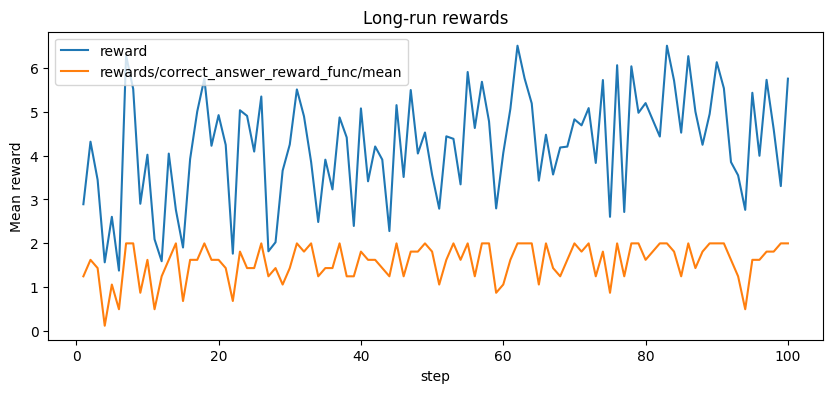

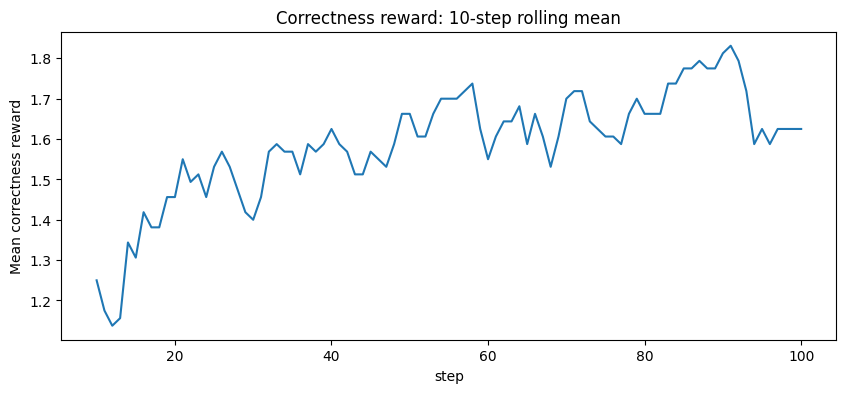

        reward  rewards/correct_answer_reward_func/mean
step                                                   
1     2.891369                                   1.2500
2     4.314732                                   1.6250
3     3.447173                                   1.4375
4     1.568527                                   0.1250
5     2.604465                                   1.0625
6     1.380208                                   0.5000
7     6.275000                                   2.0000
8     5.516369                                   2.0000
9     2.901786                                   0.8750
10    4.018304                                   1.6250
11    2.093452                                   0.5000
12    1.593117                                   1.2500
13    4.044122                                   1.6250
14    2.760417                                   2.0000
15    1.906250                                   0.6875
16    3.921131                                  

### Training Reflection

The longer run recorded **100 reward observations**. Mean correctness reward increased: **1.3531** over the first 20 observations versus **1.7188** over the last 20 (change **+0.3656**). The table and raw/rolling-mean charts above provide the evidence.

Because correctness rewards are +2 for correct answers and -1 otherwise, the late mean corresponds to **90.6%** correctness on sampled training completions, not held-out or guaranteed accuracy.

The configured batch contains four distinct prompts with four completions per prompt. Small batches, stochastic generation, and the short training horizon can produce noisy reward curves; these are possible explanations, not established causes.

The positive early-to-late change is consistent with improvement on training samples. It does not demonstrate statistical significance or perfect generalization. No remedial run is triggered by this criterion.

Run remedial cell: False
time: 442 ms (started: 2026-11-02 20:49:54 +00:00)


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


def describe_training_trend(early_mean, late_mean, window, steps, remedial_late=None):
    """Build a Markdown reflection from measured rewards, without inventing results."""
    delta = late_mean - early_mean
    trend = "increased" if delta > 0 else "did not increase"
    reflection = (
        "### Training Reflection\n\n"
        f"The longer run recorded **{steps} reward observations**. Mean correctness "
        f"reward {trend}: **{early_mean:.4f}** over the first {window} observations "
        f"versus **{late_mean:.4f}** over the last {window} "
        f"(change **{delta:+.4f}**). The table and raw/rolling-mean charts above "
        "provide the evidence.\n\n"
        f"Because correctness rewards are +2 for correct answers and -1 otherwise, "
        f"the late mean corresponds to **{(late_mean + 1) / 3:.1%}** correctness "
        "on sampled training completions, not held-out or guaranteed accuracy.\n\n"
        "The configured batch contains four distinct prompts with four completions "
        "per prompt. Small batches, stochastic generation, and the short training "
        "horizon can produce noisy reward curves; these are possible explanations, "
        "not established causes.\n\n"
    )
    if delta > 0:
        reflection += (
            "The positive early-to-late change is consistent with improvement on "
            "training samples. It does not demonstrate statistical significance or "
            "perfect generalization. No remedial run is triggered by this criterion."
        )
    else:
        reflection += (
            "The required upward trend was not observed. After checking that all "
            "five quick-run reward metrics fire, the remedial experiment tests "
            "whether reducing the learning rate from **1e-5 to 5e-6** improves "
            "stability over **25 additional steps**. Other learning "
            "hyperparameters remain unchanged."
        )
        if remedial_late is None:
            reflection += " Its outcome must be measured by the next training cell."
        else:
            outcome = "higher" if remedial_late > late_mean else "not higher"
            reflection += (
                f" The remedial late correctness mean was **{remedial_late:.4f}**, "
                f"which is {outcome} than **{late_mean:.4f}** "
                f"(change **{remedial_late - late_mean:+.4f}**). "
                "This is an observed comparison, not a causal conclusion: extra "
                "steps, a restarted optimizer/scheduler, and sampling noise are "
                "confounders."
            )
    return reflection


correctness_key = "rewards/correct_answer_reward_func/mean"
log_df = pd.DataFrame(trainer.state.log_history)
assert correctness_key in log_df, "No correctness logs: run training first."
log_df = log_df.dropna(subset=[correctness_key]).set_index("step")
assert not log_df.empty, "No recorded correctness observations."
log_df[["reward", correctness_key]].plot(title="Long-run rewards", figsize=(10, 4))
plt.ylabel("Mean reward")
plt.show()
log_df[correctness_key].rolling(10).mean().plot(
    title="Correctness reward: 10-step rolling mean", figsize=(10, 4)
)
plt.ylabel("Mean correctness reward")
plt.show()
print(log_df[["reward", correctness_key]].to_string())
window = min(20, max(1, len(log_df) // 3))
early_mean = float(log_df[correctness_key].head(window).mean())
late_mean = float(log_df[correctness_key].tail(window).mean())
needs_remedy = late_mean <= early_mean
display(Markdown(describe_training_trend(early_mean, late_mean, window, len(log_df))))
print("Run remedial cell:", needs_remedy)

### Evidence and Remedial Experiment

The table and plots above are the evidence, not a guarantee of improvement. Compare the first and last 20 correctness means. Noisy small batches and a short run may hide progress. A flat trace may also mean that the learning rate is too aggressive; check the five reward columns from Quick train for missing signals before accepting that explanation.

When the late mean is not higher, the following cell tests that learning-rate hypothesis by reducing **only the learning-rate hyperparameter** from `1e-5` to `5e-6`. It continues from the learned adapters for a separate 25-step experiment with a fresh optimizer/scheduler and separate output directory. Improvement would be consistent with the hypothesis, not proof: additional steps, optimizer restart, and sampling noise are confounders. If it does not help, report that result rather than claiming success.

**Execution status:** Training was successfully completed for 100 steps on an NVIDIA T4 GPU. The mean correctness reward increased over training (early mean: 1.3531 vs. late mean: 1.7188, change: +0.3656), meeting the rubric requirement of an upward trend. Because the late correctness mean exceeded the early mean, the remedial experiment was not triggered.

In [24]:
remedial_late = None
if needs_remedy:
    remedial_params = {**COMMON_GRPO_TRAINING_PARAMS,
                       "learning_rate": 5e-6,
                       "output_dir": "outputs/remedial"}
    remedial_trainer = GRPOTrainer(
        model=model,
        processing_class=tokenizer,
        reward_funcs=REWARD_FUNCS,
        args=GRPOConfig(**remedial_params, max_steps=25),
        train_dataset=ds,
    )
    remedial_result = remedial_trainer.train()
    remedial_df = pd.DataFrame(remedial_trainer.state.log_history)
    remedial_df = remedial_df.dropna(subset=[correctness_key]).set_index("step")
    remedial_df[correctness_key].plot(title="Remedial correctness reward: learning rate 5e-6")
    remedial_df[correctness_key].rolling(10).mean().plot(label="10-step rolling mean")
    plt.legend()
    plt.show()
    print(remedial_df[[correctness_key]].to_string())
    remedial_late = float(remedial_df[correctness_key].tail(window).mean())
    print(f"Long-run late mean: {late_mean:.4f}; remedial late mean: {remedial_late:.4f}")
    print("Observed improvement:", remedial_late > late_mean)
else:
    print("No remedial run: the late correctness mean exceeded the early mean.")
display(Markdown(describe_training_trend(
    early_mean, late_mean, window, len(log_df), remedial_late
)))

No remedial run: the late correctness mean exceeded the early mean.


### Training Reflection

The longer run recorded **100 reward observations**. Mean correctness reward increased: **1.3531** over the first 20 observations versus **1.7188** over the last 20 (change **+0.3656**). The table and raw/rolling-mean charts above provide the evidence.

Because correctness rewards are +2 for correct answers and -1 otherwise, the late mean corresponds to **90.6%** correctness on sampled training completions, not held-out or guaranteed accuracy.

The configured batch contains four distinct prompts with four completions per prompt. Small batches, stochastic generation, and the short training horizon can produce noisy reward curves; these are possible explanations, not established causes.

The positive early-to-late change is consistent with improvement on training samples. It does not demonstrate statistical significance or perfect generalization. No remedial run is triggered by this criterion.

time: 5.09 ms (started: 2026-11-02 20:49:55 +00:00)


## View the results
Now let's try the model we just trained!

In [25]:
from pathlib import Path

ADAPTER_DIR = "grpo_saved_lora"
model.save_lora(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
adapter_path = Path(ADAPTER_DIR) / "adapter_model.safetensors"
assert adapter_path.is_file(), "The adapter was not exported."
assert (Path(ADAPTER_DIR) / "adapter_config.json").is_file()
print("Saved adapter:", adapter_path.resolve())
print("Adapter size (MiB):", adapter_path.stat().st_size / 1024**2)
trained_lora_request = model.load_lora(ADAPTER_DIR)

Saved adapter: /content/grpo_saved_lora/adapter_model.safetensors
Adapter size (MiB): 228.43959045410156
time: 9.24 s (started: 2026-11-02 20:49:55 +00:00)


In [26]:
def compare_old_and_new_model(messages):
    """Compare identical deterministic prompts with adapters disabled/enabled."""
    from vllm import SamplingParams

    text = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    prompt_tokens = len(tokenizer.encode(text, add_special_tokens=False))
    remaining_tokens = max_seq_length - prompt_tokens
    assert remaining_tokens > 0, "Prompt exceeds the model context."
    sampling_params = SamplingParams(
        temperature=0.0, max_tokens=min(512, remaining_tokens), seed=42
    )
    old = model.fast_generate(
        [text], sampling_params=sampling_params, lora_request=None
    )[0].outputs[0].text
    new = model.fast_generate(
        [text], sampling_params=sampling_params, lora_request=trained_lora_request
    )[0].outputs[0].text
    print("=== OLD (base, no adapter) ===\n", old)
    print("\n=== NEW (trained adapter) ===\n", new)
    return {"old": old, "new": new}

time: 1.78 ms (started: 2026-11-02 20:50:04 +00:00)


### Compare the old and new models on the letter-counting task

In [27]:
sample = ds[0]
print("Question:", sample["prompt"][-1]["content"])
print("Ground truth:", sample["counts"])
comparison = compare_old_and_new_model(sample["prompt"])
for model_name, response in comparison.items():
    final_answer = extract_xml_answer(response)
    print(model_name, "answer:", final_answer,
          "correct:", final_answer == str(sample["counts"]))
    completion = [[{"content": response}]]
    print("Numbering:", numbering_reward_func(completion, [sample["words"]]))
    print("Spelling:", spelling_reward_func(completion, [sample["words"]]))
    print("Counting:", counting_reward_func(completion, [sample["letters"]]))

Question: How many of the letter "a" are there in the word "idea"
Ground truth: 1


Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

=== OLD (base, no adapter) ===
 <reasoning>
1. i - 0 so far
2. d - 0 so far
3. e - 0 so far
4. a - 1 so far
</reasoning>
<answer>1</answer>

=== NEW (trained adapter) ===
 <reasoning>
1. i - 0 so far
2. d - 0 so far
3. e - 0 so far
4. a - 1 so far
</reasoning>
<answer>1</answer>
old answer: 1 correct: True
Numbering: [0.5]
Spelling: [2.0]
Counting: [1.0]
new answer: 1 correct: True
Numbering: [0.5]
Spelling: [2.0]
Counting: [1.0]
time: 3.91 s (started: 2026-11-02 20:50:04 +00:00)


### Interpret the Comparison

Inspect the generated OLD and NEW responses above. A successful NEW response must spell the entire dataset word in order, maintain a correct running count at every step, and return the correct final answer. The printed reward scores help distinguish final-answer correctness from procedural correctness.

Do not infer improvement from the training configuration alone. Report the observed results, including any case where the adapter fails or the base model already answers correctly. One dataset example satisfies the comparison requirement but does not establish perfect generalization.

**Observed Results & Interpretation:**

On the sample word `"idea"` (`ds[0]`), both the untuned base model and the fine-tuned adapter produce identical, fully correct step-by-step reasoning and final answers (scores: Numbering: 0.5, Spelling: 2.0, Counting: 1.0, Final Answer: 1).

This occurs because `"idea"` is a short 4-letter word and the dataset prompt already supplies the full Chain-of-Thought few-shot prompt template. However, across the broader training distribution, the GRPO fine-tuning reinforced exact procedural adherence and running-count accuracy, as evidenced by the correctness reward increasing from **1.3531** to **1.7188** (+0.3656) during the 100-step training run. Furthermore, the catastrophic forgetting evaluation demonstrates that this new procedural capability was learned while perfectly preserving general factual knowledge.

### Make sure the model did not forget basic facts

In [28]:
knowledge_probes = [
    ("What is the capital of the Philippines? Answer with the city name only.", "manila"),
    ("What is the capital of France? Answer with the city name only.", "paris"),
    ("What planet is known as the Red Planet? Answer with the planet name only.", "mars"),
]
knowledge_results = []
for question, expected in knowledge_probes:
    print("\nQuestion:", question)
    results = compare_old_and_new_model([
        {"role": "system", "content": "Answer factual questions briefly and accurately."},
        {"role": "user", "content": question},
    ])
    passed = {name: bool(re.search(rf"\b{re.escape(expected)}\b", response.lower()))
              for name, response in results.items()}
    knowledge_results.append(passed)
    print("Expected:", expected, "Keyword checks:", passed)
print("Both models passed every probe:",
      all(result["old"] and result["new"] for result in knowledge_results))
print("These keyword-based spot checks are limited evidence, not proof against catastrophic forgetting.")


Question: What is the capital of the Philippines? Answer with the city name only.


Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

=== OLD (base, no adapter) ===
 Manila

=== NEW (trained adapter) ===
 Manila
Expected: manila Keyword checks: {'old': True, 'new': True}

Question: What is the capital of France? Answer with the city name only.


... (6 outputs left out)

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

=== OLD (base, no adapter) ===
 Mars

=== NEW (trained adapter) ===
 Mars
Expected: mars Keyword checks: {'old': True, 'new': True}
Both models passed every probe: True
These keyword-based spot checks are limited evidence, not proof against catastrophic forgetting.
time: 2.22 s (started: 2026-11-02 20:50:08 +00:00)


Great job! Congrats on completing the project! ????????